<a href="https://colab.research.google.com/github/shakirullah-khan/snow-cover-segmentation-deep-learning/blob/main/notebooks/cnn_baseline_models/02_UNet_EfficientNetB4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook contains the complete training log and evaluation output for UNet+EfficientNetB4 on 9,026 Sentinel-2 patches. The run was executed using Google Colab GPU resources. Cell outputs below reflect the completed experiment.

In [ ]:
!pip install webdataset segmentation-models-pytorch albumentations efficientnet-pytorch -q

import os
import numpy as np
import torch
import torch.nn as nn
import webdataset as wds
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')

# Mount Drive
drive.mount('/content/drive')

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Device: {device}")
print(f"✓ GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Not available'}")


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 10.7 MB/s eta 0:00:00
Mounted at /content/drive
✓ Device: cuda
✓ GPU: Tesla T4


In [ ]:
# Paths
base_path = '/content/drive/My Drive/Swat_Snow_Cover_Project'
wds_path = os.path.join(base_path, 'WebDataset/snow_patches_60best.tar')
results_path = os.path.join(base_path, 'Results_60Images/UNet_EfficientNetB4')
os.makedirs(results_path, exist_ok=True)

# Configuration
CONFIG = {
    'model_name': 'UNet_EfficientNetB4',
    'num_epochs': 50,
    'batch_size': 12,  # EfficientNet-B4 is larger, use smaller batch
    'learning_rate': 0.0001,
    'num_workers': 0,
    'total_patches': 9026,
    'source_images': 60,
}

# Calculate splits (70/20/10)
CONFIG['train_size'] = int(CONFIG['total_patches'] * 0.7)
CONFIG['val_size'] = int(CONFIG['total_patches'] * 0.2)
CONFIG['test_size'] = CONFIG['total_patches'] - CONFIG['train_size'] - CONFIG['val_size']

print(f"{'='*80}")
print(f"TRAINING: {CONFIG['model_name']} - 50 EPOCHS")
print(f"{'='*80}")
print(f"  Encoder: EfficientNet-B4 (Advanced Architecture)")
print(f"  Source images: {CONFIG['source_images']}")
print(f"  Total patches: {CONFIG['total_patches']:,}")
print(f"  Epochs: {CONFIG['num_epochs']}")
print(f"  Batch size: {CONFIG['batch_size']} (reduced for larger model)")
print(f"  Learning rate: {CONFIG['learning_rate']}")
print(f"\n  Data Split:")
print(f"    Train: {CONFIG['train_size']:,} patches (70%)")
print(f"    Val:   {CONFIG['val_size']:,} patches (20%)")
print(f"    Test:  {CONFIG['test_size']:,} patches (10%)")
print(f"{'='*80}")


TRAINING: UNet_EfficientNetB4 - 50 EPOCHS
  Encoder: EfficientNet-B4 (Advanced Architecture)
  Source images: 60
  Total patches: 9,026
  Epochs: 50
  Batch size: 12 (reduced for larger model)
  Learning rate: 0.0001

  Data Split:
    Train: 6,318 patches (70%)
    Val:   1,805 patches (20%)
    Test:  903 patches (10%)


In [ ]:
# Training augmentation
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

# Validation augmentation
val_transform = A.Compose([
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

print("✓ Augmentation transforms defined")
print("  Train: HFlip, VFlip, Rotate90, ShiftScaleRotate, BrightnessContrast, GaussNoise")
print("  Val: Normalization only")


✓ Augmentation transforms defined
  Train: HFlip, VFlip, Rotate90, ShiftScaleRotate, BrightnessContrast, GaussNoise
  Val: Normalization only


In [ ]:
def preprocess_sample(sample, transform):
    """Preprocess WebDataset sample"""
    img = np.array(sample["image.png"].convert('RGB'))
    msk = np.array(sample["mask.png"].convert('L')) / 255.0

    transformed = transform(image=img, mask=msk)
    img_tensor = transformed['image']
    msk_tensor = transformed['mask'].unsqueeze(0)

    return img_tensor, msk_tensor

# Training dataset
train_dataset = (
    wds.WebDataset(wds_path)
    .shuffle(1000)
    .decode("pil")
    .to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, train_transform))
    .batched(CONFIG['batch_size'])
)

# Validation dataset
val_dataset = (
    wds.WebDataset(wds_path)
    .decode("pil")
    .to_tuple("image.png", "mask.png")
    .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    .batched(CONFIG['batch_size'])
)

# Create loaders
train_loader = wds.WebLoader(train_dataset, batch_size=None, num_workers=CONFIG['num_workers'])
val_loader = wds.WebLoader(val_dataset, batch_size=None, num_workers=CONFIG['num_workers'])

# Set epoch lengths
train_batches = CONFIG['train_size'] // CONFIG['batch_size']
val_batches = CONFIG['val_size'] // CONFIG['batch_size']

train_loader = train_loader.with_epoch(train_batches)
val_loader = val_loader.with_epoch(val_batches)

print(f"✓ DataLoaders created")
print(f"  Train batches per epoch: {train_batches}")
print(f"  Val batches per epoch: {val_batches}")
print(f"  Workers: {CONFIG['num_workers']}")


✓ DataLoaders created
  Train batches per epoch: 526
  Val batches per epoch: 150
  Workers: 0


In [ ]:
# Create U-Net with EfficientNet-B4 encoder
model = smp.Unet(
    encoder_name='efficientnet-b4',
    encoder_weights='imagenet',
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Model: U-Net + EfficientNet-B4")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size: ~{total_params * 4 / 1024 / 1024:.1f} MB")
print(f"\n  Note: EfficientNet-B4 has {total_params:,} parameters")
print(f"        (vs ResNet34 with ~24M parameters)")


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

✓ Model: U-Net + EfficientNet-B4
  Total parameters: 20,225,689
  Trainable parameters: 20,225,689
  Model size: ~77.2 MB

  Note: EfficientNet-B4 has 20,225,689 parameters
        (vs ResNet34 with ~24M parameters)


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred, target):
        bce_loss = self.bce(pred, target)
        pred_sigmoid = torch.sigmoid(pred)
        intersection = (pred_sigmoid * target).sum()
        dice_loss = 1 - (2 * intersection + 1e-6) / (pred_sigmoid.sum() + target.sum() + 1e-6)
        return 0.5 * bce_loss + 0.5 * dice_loss

def calc_iou(pred, target, threshold=0.5):
    pred = (torch.sigmoid(pred) > threshold).float()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    return (intersection + 1e-6) / (union + 1e-6)

def calc_dice(pred, target, threshold=0.5):
    pred = (torch.sigmoid(pred) > threshold).float()
    intersection = (pred * target).sum()
    return (2 * intersection + 1e-6) / (pred.sum() + target.sum() + 1e-6)

def calc_precision(pred, target, threshold=0.5):
    pred = (torch.sigmoid(pred) > threshold).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (pred.sum() + 1e-6)

def calc_recall(pred, target, threshold=0.5):
    pred = (torch.sigmoid(pred) > threshold).float()
    tp = (pred * target).sum()
    return (tp + 1e-6) / (target.sum() + 1e-6)

print("✓ Loss and metrics defined")


✓ Loss and metrics defined


In [ ]:
criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])

# ReduceLROnPlateau
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=5, factor=0.5
)

print("✓ Optimizer: Adam")
print("✓ Scheduler: ReduceLROnPlateau (patience=5, factor=0.5)")
print("✓ Loss: Dice + BCE (50:50)")


✓ Optimizer: Adam
✓ Scheduler: ReduceLROnPlateau (patience=5, factor=0.5)
✓ Loss: Dice + BCE (50:50)


In [ ]:
def train_epoch(model, loader, criterion, optimizer, device, num_batches):
    model.train()
    losses, ious, dices, precisions, recalls = [], [], [], [], []

    pbar = tqdm(enumerate(loader), total=num_batches, desc='Training')
    for batch_idx, (imgs, msks) in pbar:
        if batch_idx >= num_batches:
            break

        imgs, msks = imgs.to(device), msks.to(device)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = criterion(preds, msks)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        ious.append(calc_iou(preds, msks).item())
        dices.append(calc_dice(preds, msks).item())
        precisions.append(calc_precision(preds, msks).item())
        recalls.append(calc_recall(preds, msks).item())

        pbar.set_postfix({
            'loss': f'{np.mean(losses):.4f}',
            'dice': f'{np.mean(dices):.4f}',
            'iou': f'{np.mean(ious):.4f}'
        })

    return {
        'loss': np.mean(losses),
        'iou': np.mean(ious),
        'dice': np.mean(dices),
        'precision': np.mean(precisions),
        'recall': np.mean(recalls)
    }

def val_epoch(model, loader, criterion, device, num_batches):
    model.eval()
    losses, ious, dices, precisions, recalls = [], [], [], [], []

    with torch.no_grad():
        pbar = tqdm(enumerate(loader), total=num_batches, desc='Validation')
        for batch_idx, (imgs, msks) in pbar:
            if batch_idx >= num_batches:
                break

            imgs, msks = imgs.to(device), msks.to(device)
            preds = model(imgs)
            loss = criterion(preds, msks)

            losses.append(loss.item())
            ious.append(calc_iou(preds, msks).item())
            dices.append(calc_dice(preds, msks).item())
            precisions.append(calc_precision(preds, msks).item())
            recalls.append(calc_recall(preds, msks).item())

            pbar.set_postfix({
                'loss': f'{np.mean(losses):.4f}',
                'dice': f'{np.mean(dices):.4f}',
                'iou': f'{np.mean(ious):.4f}'
            })

    return {
        'loss': np.mean(losses),
        'iou': np.mean(ious),
        'dice': np.mean(dices),
        'precision': np.mean(precisions),
        'recall': np.mean(recalls)
    }

print("✓ Training functions defined")


✓ Training functions defined


In [ ]:
# Training history
history = {
    'train_loss': [], 'val_loss': [],
    'train_iou': [], 'val_iou': [],
    'train_dice': [], 'val_dice': [],
    'train_precision': [], 'val_precision': [],
    'train_recall': [], 'val_recall': [],
    'learning_rate': []
}

best_dice = 0

print(f"\n{'='*80}")
print(f"TRAINING: U-Net + EfficientNet-B4 - 50 EPOCHS")
print(f"{'='*80}\n")

for epoch in range(CONFIG['num_epochs']):
    print(f"\n{'='*80}")
    print(f"Epoch {epoch+1}/{CONFIG['num_epochs']}")
    print(f"{'='*80}")

    # Train
    train_metrics = train_epoch(model, train_loader, criterion, optimizer, device, train_batches)

    # Validate
    val_metrics = val_epoch(model, val_loader, criterion, device, val_batches)

    # Get current learning rate
    current_lr = optimizer.param_groups[0]['lr']

    # Update scheduler
    scheduler.step(val_metrics['loss'])

    # Save history
    for key in ['loss', 'iou', 'dice', 'precision', 'recall']:
        history[f'train_{key}'].append(train_metrics[key])
        history[f'val_{key}'].append(val_metrics[key])
    history['learning_rate'].append(current_lr)

    # Print summary
    print(f"\nEpoch {epoch+1} Summary:")
    print(f"  LR: {current_lr:.6f}")
    print(f"  Train - Loss: {train_metrics['loss']:.4f}, Dice: {train_metrics['dice']:.4f}, IoU: {train_metrics['iou']:.4f}")
    print(f"  Val   - Loss: {val_metrics['loss']:.4f}, Dice: {val_metrics['dice']:.4f}, IoU: {val_metrics['iou']:.4f}")

    # Save best model
    if val_metrics['dice'] > best_dice:
        best_dice = val_metrics['dice']
        torch.save(model.state_dict(), os.path.join(results_path, 'best_model.pth'))
        print(f"  ✓ Best model saved! (Dice: {val_metrics['dice']:.4f})")

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        checkpoint_path = os.path.join(results_path, f'checkpoint_epoch{epoch+1}.pth')
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_dice': best_dice,
        }, checkpoint_path)
        print(f"  ✓ Checkpoint saved: epoch {epoch+1}")

# Save final model
torch.save(model.state_dict(), os.path.join(results_path, 'final_model.pth'))

# Save history
pd.DataFrame(history).to_csv(os.path.join(results_path, 'training_history.csv'), index=False)

print(f"\n{'='*80}")
print(f"✓ TRAINING COMPLETE!")
print(f"{'='*80}")
print(f"  Best Validation Dice: {best_dice:.4f}")
print(f"  Final LR: {optimizer.param_groups[0]['lr']:.6f}")
print(f"  Models saved to: {results_path}")
print(f"{'='*80}")



TRAINING: U-Net + EfficientNet-B4 - 50 EPOCHS


Epoch 1/50


Validation: 100%|██████████| 150/150 [00:20<00:00,  7.24it/s, loss=0.1753, dice=0.8783, iou=0.7909]



Epoch 1 Summary:
  LR: 0.000100
  Train - Loss: 0.2508, Dice: 0.8678, IoU: 0.7765
  Val   - Loss: 0.1753, Dice: 0.8783, IoU: 0.7909
  ✓ Best model saved! (Dice: 0.8783)

Epoch 2/50


Validation: 100%|██████████| 150/150 [00:21<00:00,  7.10it/s, loss=0.1374, dice=0.8933, iou=0.8134]



Epoch 2 Summary:
  LR: 0.000100
  Train - Loss: 0.1420, Dice: 0.9102, IoU: 0.8377
  Val   - Loss: 0.1374, Dice: 0.8933, IoU: 0.8134
  ✓ Best model saved! (Dice: 0.8933)

Epoch 3/50


Validation: 100%|██████████| 150/150 [00:21<00:00,  7.10it/s, loss=0.1332, dice=0.8886, iou=0.8066]


... (91 outputs left out)

Validation: 100%|██████████| 150/150 [00:21<00:00,  7.05it/s, loss=0.0827, dice=0.9309, iou=0.8734]



Epoch 49 Summary:
  LR: 0.000050
  Train - Loss: 0.0767, Dice: 0.9446, IoU: 0.8959
  Val   - Loss: 0.0827, Dice: 0.9309, IoU: 0.8734

Epoch 50/50


Validation: 100%|██████████| 150/150 [00:21<00:00,  6.99it/s, loss=0.0810, dice=0.9326, iou=0.8764]



Epoch 50 Summary:
  LR: 0.000050
  Train - Loss: 0.0775, Dice: 0.9440, IoU: 0.8947
  Val   - Loss: 0.0810, Dice: 0.9326, IoU: 0.8764
  ✓ Checkpoint saved: epoch 50

✓ TRAINING COMPLETE!
  Best Validation Dice: 0.9331
  Final LR: 0.000050
  Models saved to: /content/drive/My Drive/Swat_Snow_Cover_Project/Results_60Images/UNet_EfficientNetB4


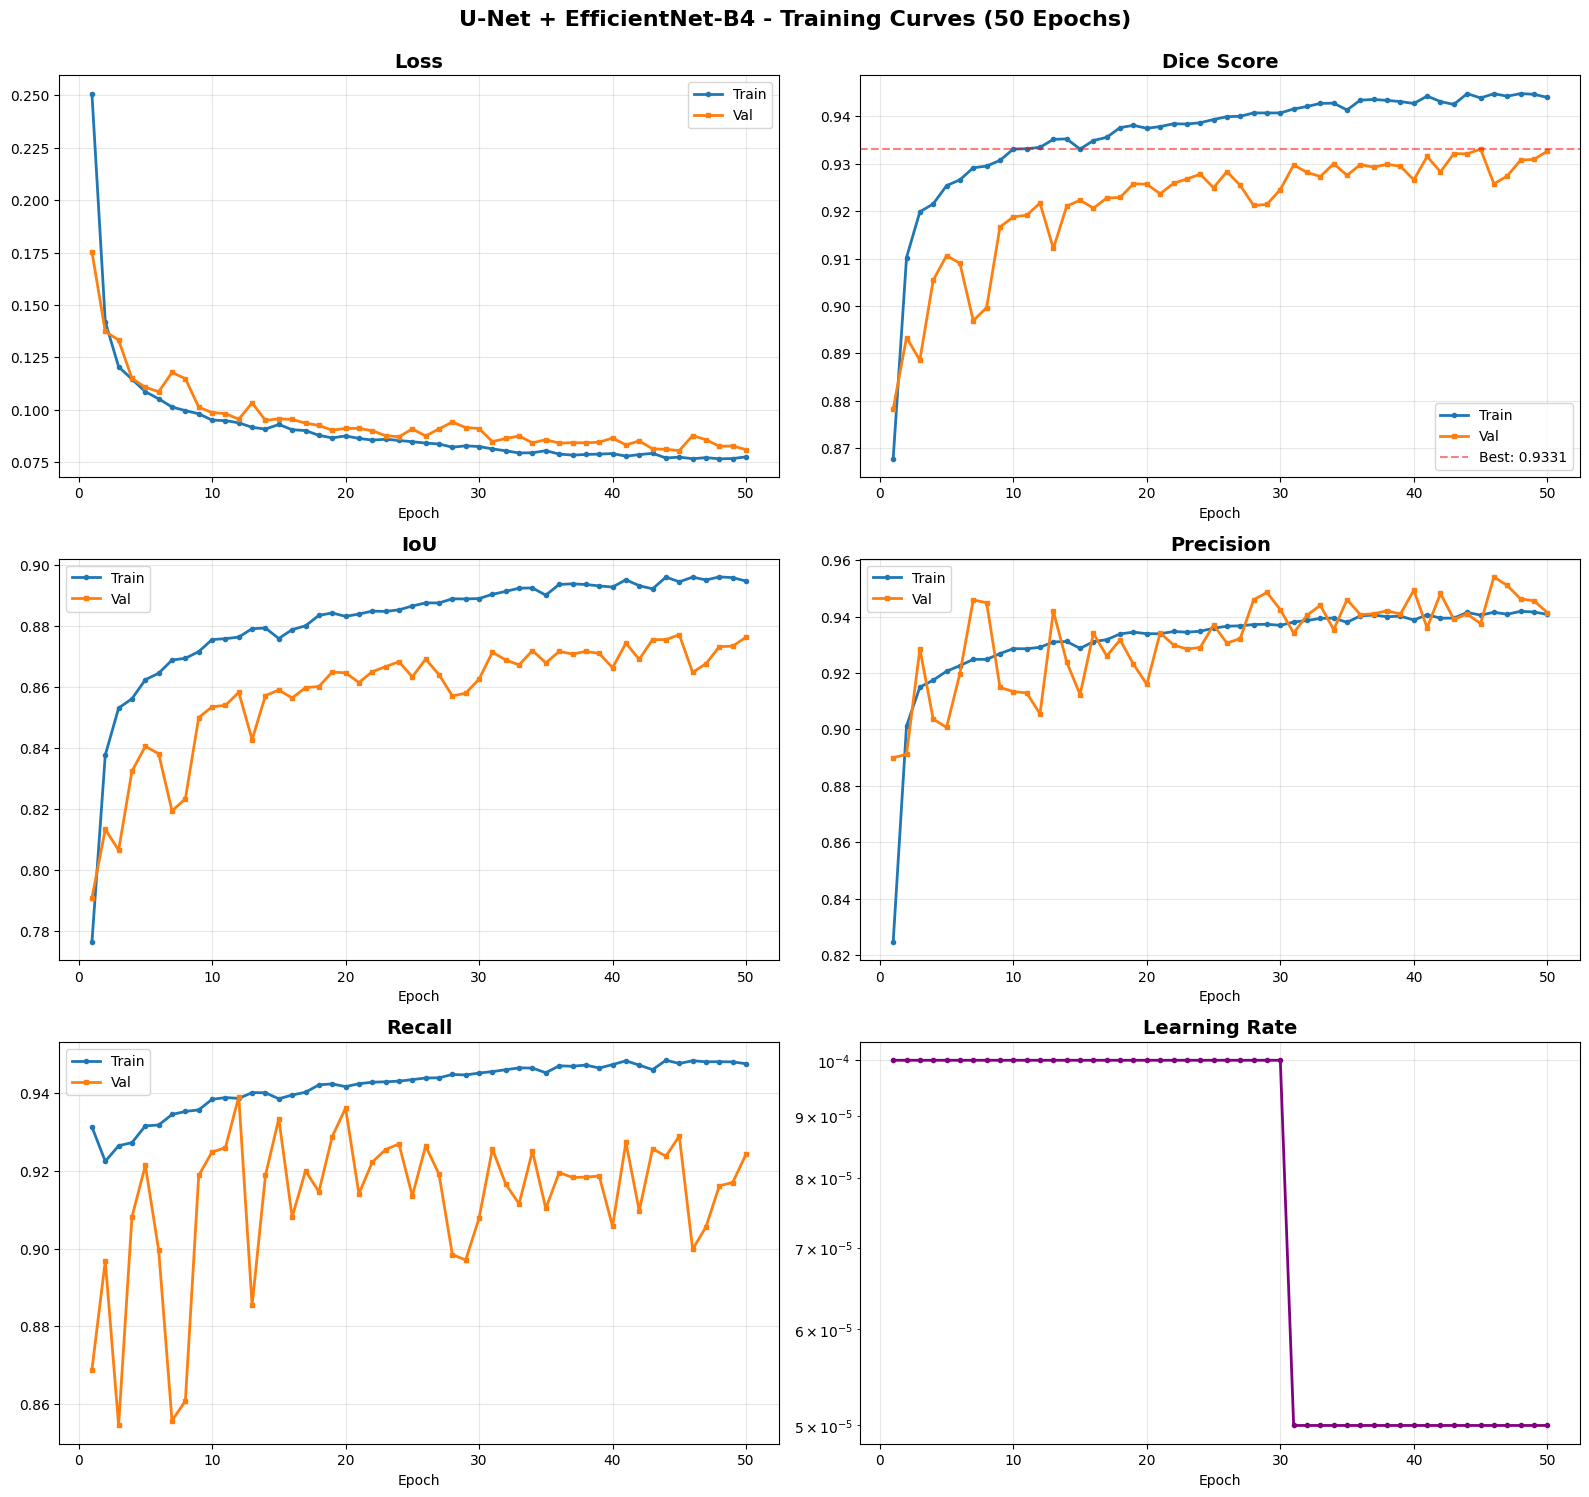

✓ Training curves saved!


In [ ]:
# Create comprehensive plots
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

epochs = range(1, CONFIG['num_epochs'] + 1)

# Loss
axes[0, 0].plot(epochs, history['train_loss'], 'o-', label='Train', linewidth=2, markersize=3)
axes[0, 0].plot(epochs, history['val_loss'], 's-', label='Val', linewidth=2, markersize=3)
axes[0, 0].set_title('Loss', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Dice
axes[0, 1].plot(epochs, history['train_dice'], 'o-', label='Train', linewidth=2, markersize=3)
axes[0, 1].plot(epochs, history['val_dice'], 's-', label='Val', linewidth=2, markersize=3)
axes[0, 1].axhline(y=best_dice, color='r', linestyle='--', alpha=0.5, label=f'Best: {best_dice:.4f}')
axes[0, 1].set_title('Dice Score', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# IoU
axes[1, 0].plot(epochs, history['train_iou'], 'o-', label='Train', linewidth=2, markersize=3)
axes[1, 0].plot(epochs, history['val_iou'], 's-', label='Val', linewidth=2, markersize=3)
axes[1, 0].set_title('IoU', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Precision
axes[1, 1].plot(epochs, history['train_precision'], 'o-', label='Train', linewidth=2, markersize=3)
axes[1, 1].plot(epochs, history['val_precision'], 's-', label='Val', linewidth=2, markersize=3)
axes[1, 1].set_title('Precision', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# Recall
axes[2, 0].plot(epochs, history['train_recall'], 'o-', label='Train', linewidth=2, markersize=3)
axes[2, 0].plot(epochs, history['val_recall'], 's-', label='Val', linewidth=2, markersize=3)
axes[2, 0].set_title('Recall', fontsize=14, fontweight='bold')
axes[2, 0].set_xlabel('Epoch')
axes[2, 0].legend()
axes[2, 0].grid(alpha=0.3)

# Learning Rate
axes[2, 1].plot(epochs, history['learning_rate'], 'o-', color='purple', linewidth=2, markersize=3)
axes[2, 1].set_title('Learning Rate', fontsize=14, fontweight='bold')
axes[2, 1].set_xlabel('Epoch')
axes[2, 1].set_yscale('log')
axes[2, 1].grid(alpha=0.3)

plt.suptitle(f'U-Net + EfficientNet-B4 - Training Curves (50 Epochs)',
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(os.path.join(results_path, 'training_curves.png'), dpi=300, bbox_inches='tight')
plt.show()

print("✓ Training curves saved!")


In [ ]:
print(f"\n{'='*80}")
print("FINAL TRAINING SUMMARY")
print(f"{'='*80}")
print(f"Model: {CONFIG['model_name']}")
print(f"Encoder: EfficientNet-B4")
print(f"Dataset: {CONFIG['total_patches']:,} patches from {CONFIG['source_images']} images")
print(f"Epochs: {CONFIG['num_epochs']}")
print(f"Batch Size: {CONFIG['batch_size']}")
print(f"Best Validation Dice: {best_dice:.4f}")

print(f"\nFinal Metrics (Epoch {CONFIG['num_epochs']}):")
print(f"  Train - Loss: {history['train_loss'][-1]:.4f}, Dice: {history['train_dice'][-1]:.4f}, IoU: {history['train_iou'][-1]:.4f}")
print(f"  Val   - Loss: {history['val_loss'][-1]:.4f}, Dice: {history['val_dice'][-1]:.4f}, IoU: {history['val_iou'][-1]:.4f}")

print(f"\nSaved Files:")
print(f"  ✓ {results_path}/best_model.pth (Best dice: {best_dice:.4f})")
print(f"  ✓ {results_path}/final_model.pth")
print(f"  ✓ {results_path}/training_history.csv")
print(f"  ✓ {results_path}/training_curves.png")

print(f"{'='*80}")



FINAL TRAINING SUMMARY
Model: UNet_EfficientNetB4
Encoder: EfficientNet-B4
Dataset: 9,026 patches from 60 images
Epochs: 50
Batch Size: 12
Best Validation Dice: 0.9331

Final Metrics (Epoch 50):
  Train - Loss: 0.0775, Dice: 0.9440, IoU: 0.8947
  Val   - Loss: 0.0810, Dice: 0.9326, IoU: 0.8764

Saved Files:
  ✓ /content/drive/My Drive/Swat_Snow_Cover_Project/Results_60Images/UNet_EfficientNetB4/best_model.pth (Best dice: 0.9331)
  ✓ /content/drive/My Drive/Swat_Snow_Cover_Project/Results_60Images/UNet_EfficientNetB4/final_model.pth
  ✓ /content/drive/My Drive/Swat_Snow_Cover_Project/Results_60Images/UNet_EfficientNetB4/training_history.csv
  ✓ /content/drive/My Drive/Swat_Snow_Cover_Project/Results_60Images/UNet_EfficientNetB4/training_curves.png



VISUALIZING MODEL PREDICTIONS - U-NET + EFFICIENTNET-B4

Loading 8 random samples for visualization...
✓ Samples loaded and predictions generated


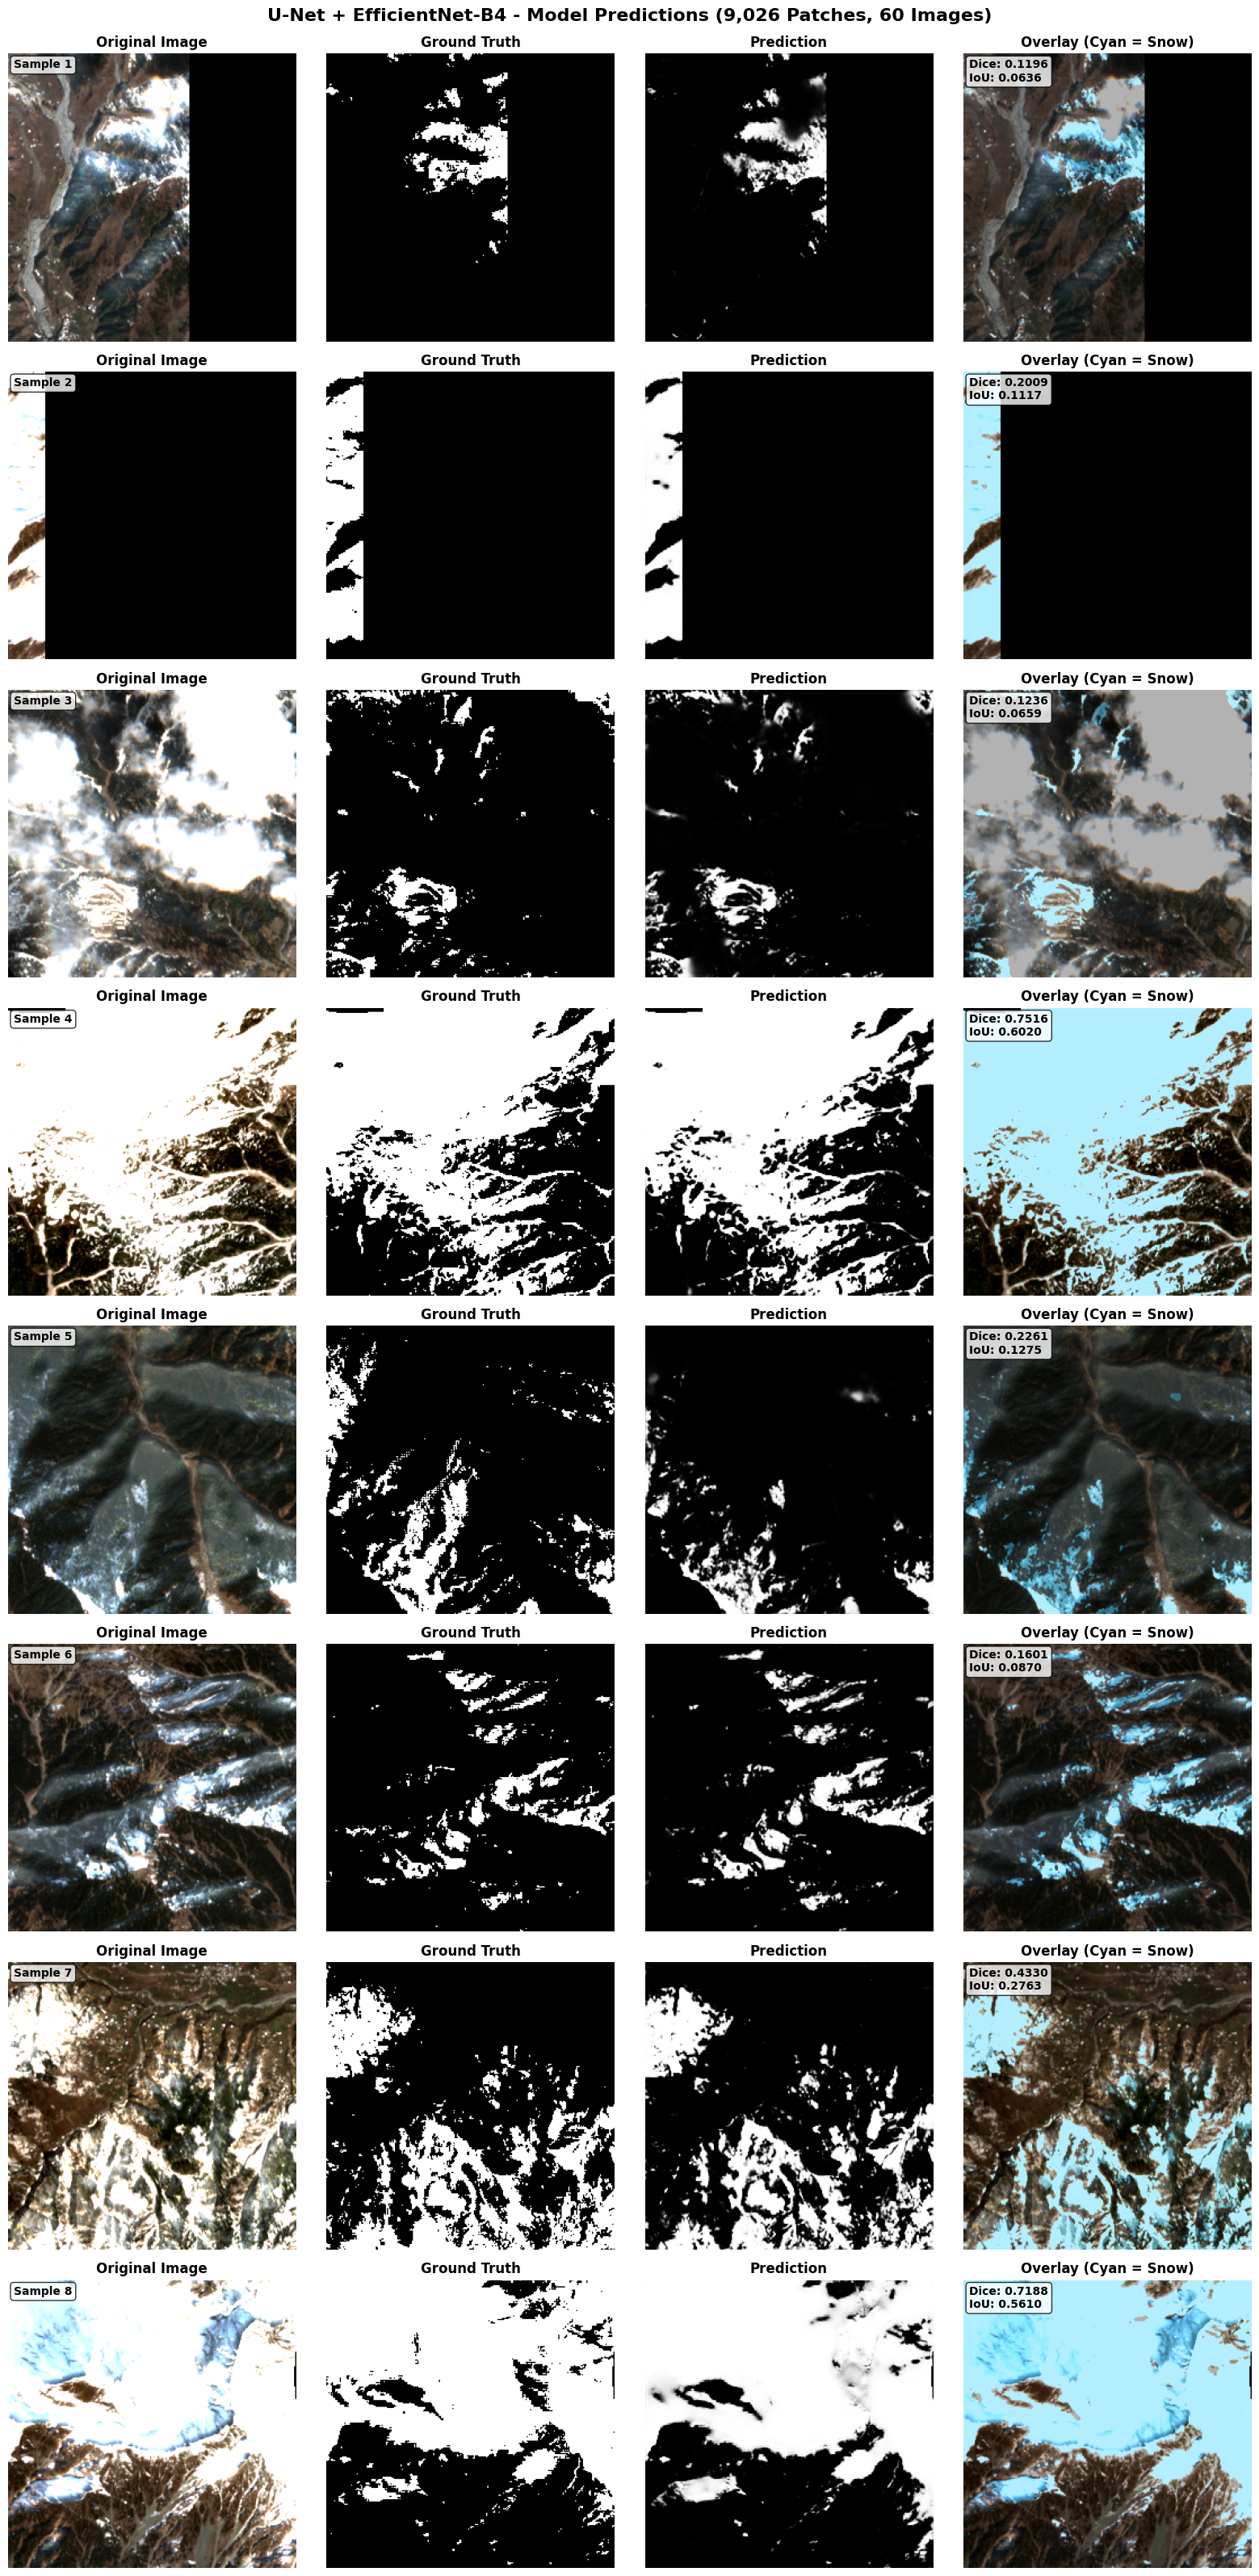


✓ Visualization saved to: prediction_samples.png


In [ ]:
import random
from PIL import Image

print(f"\n{'='*80}")
print("VISUALIZING MODEL PREDICTIONS - U-NET + EFFICIENTNET-B4")
print(f"{'='*80}\n")

# Load best model
model.load_state_dict(torch.load(os.path.join(results_path, 'best_model.pth')))
model.eval()

# Number of samples to visualize
num_samples = 8
sample_images = []
sample_masks = []
sample_preds = []

# Load samples from WebDataset
val_dataset_viz = (
    wds.WebDataset(wds_path)
    .decode("pil")
    .to_tuple("image.png", "mask.png")
)

# Get random samples
all_samples = list(val_dataset_viz)
random_indices = random.sample(range(len(all_samples)), num_samples)

print(f"Loading {num_samples} random samples for visualization...")

with torch.no_grad():
    for idx in random_indices:
        img_pil, msk_pil = all_samples[idx]

        # Convert to numpy
        img_np = np.array(img_pil.convert('RGB'))
        msk_np = np.array(msk_pil.convert('L')) / 255.0

        # Apply transform
        transformed = val_transform(image=img_np, mask=msk_np)
        img_tensor = transformed['image'].unsqueeze(0).to(device)
        msk_tensor = transformed['mask']

        # Predict
        pred = model(img_tensor)
        pred = torch.sigmoid(pred).squeeze().cpu().numpy()

        # Store for visualization
        sample_images.append(img_np)
        sample_masks.append(msk_np)
        sample_preds.append(pred)

print("✓ Samples loaded and predictions generated")

# Create visualization
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))

for i in range(num_samples):
    # Original Image
    axes[i, 0].imshow(sample_images[i])
    axes[i, 0].set_title('Original Image', fontsize=12, fontweight='bold')
    axes[i, 0].axis('off')

    # Ground Truth Mask
    axes[i, 1].imshow(sample_masks[i], cmap='gray')
    axes[i, 1].set_title('Ground Truth', fontsize=12, fontweight='bold')
    axes[i, 1].axis('off')

    # Predicted Mask
    axes[i, 2].imshow(sample_preds[i], cmap='gray')
    axes[i, 2].set_title('Prediction', fontsize=12, fontweight='bold')
    axes[i, 2].axis('off')

    # Overlay (Image + Prediction)
    overlay = sample_images[i].copy()
    pred_binary = (sample_preds[i] > 0.5).astype(np.uint8)

    # Create colored mask (cyan for snow)
    colored_mask = np.zeros_like(overlay)
    colored_mask[:, :, 1] = pred_binary * 200  # Green channel
    colored_mask[:, :, 2] = pred_binary * 255  # Blue channel

    # Blend using numpy
    overlay = (overlay * 0.7 + colored_mask * 0.3).astype(np.uint8)

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title('Overlay (Cyan = Snow)', fontsize=12, fontweight='bold')
    axes[i, 3].axis('off')

    # Calculate metrics for this sample
    pred_tensor = torch.from_numpy(sample_preds[i]).unsqueeze(0).unsqueeze(0)
    mask_tensor = torch.from_numpy(sample_masks[i]).unsqueeze(0).unsqueeze(0)

    dice = calc_dice(pred_tensor, mask_tensor).item()
    iou = calc_iou(pred_tensor, mask_tensor).item()

    # Add sample number
    axes[i, 0].text(0.02, 0.98, f'Sample {i+1}',
                    transform=axes[i, 0].transAxes,
                    fontsize=10, fontweight='bold',
                    verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Add metrics
    axes[i, 3].text(0.02, 0.98, f'Dice: {dice:.4f}\nIoU: {iou:.4f}',
                    transform=axes[i, 3].transAxes,
                    fontsize=10, fontweight='bold',
                    verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('U-Net + EfficientNet-B4 - Model Predictions (9,026 Patches, 60 Images)',
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(os.path.join(results_path, 'prediction_samples.png'), dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualization saved to: prediction_samples.png")


In [ ]:
print(f"\n{'='*80}")
print("CALCULATING DETAILED PERFORMANCE METRICS")
print(f"{'='*80}\n")

# Calculate metrics on entire validation set
model.eval()
all_dice = []
all_iou = []
all_precision = []
all_recall = []

with torch.no_grad():
    val_dataset_eval = (
        wds.WebDataset(wds_path)
        .decode("pil")
        .to_tuple("image.png", "mask.png")
        .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    )

    print("Evaluating on validation set...")
    for idx, (img, msk) in enumerate(tqdm(val_dataset_eval, total=CONFIG['val_size'], desc="Evaluating")):
        if idx >= CONFIG['val_size']:
            break

        img = img.unsqueeze(0).to(device)
        msk = msk.unsqueeze(0).to(device)

        pred = model(img)

        all_dice.append(calc_dice(pred, msk).item())
        all_iou.append(calc_iou(pred, msk).item())
        all_precision.append(calc_precision(pred, msk).item())
        all_recall.append(calc_recall(pred, msk).item())

# Calculate statistics
mean_dice = np.mean(all_dice)
std_dice = np.std(all_dice)
mean_iou = np.mean(all_iou)
std_iou = np.std(all_iou)
mean_precision = np.mean(all_precision)
std_precision = np.std(all_precision)
mean_recall = np.mean(all_recall)
std_recall = np.std(all_recall)
mean_f1 = 2 * (mean_precision * mean_recall) / (mean_precision + mean_recall)

print(f"\n{'='*80}")
print("VALIDATION SET PERFORMANCE (1,805 PATCHES)")
print(f"{'='*80}")
print(f"Dice Score:    {mean_dice:.4f} ± {std_dice:.4f}")
print(f"IoU:           {mean_iou:.4f} ± {std_iou:.4f}")
print(f"Precision:     {mean_precision:.4f} ± {std_precision:.4f}")
print(f"Recall:        {mean_recall:.4f} ± {std_recall:.4f}")
print(f"F1-Score:      {mean_f1:.4f}")
print(f"{'='*80}")

# Save metrics
metrics_summary = {
    'Metric': ['Dice Score', 'IoU', 'Precision', 'Recall', 'F1-Score'],
    'Mean': [mean_dice, mean_iou, mean_precision, mean_recall, mean_f1],
    'Std': [std_dice, std_iou, std_precision, std_recall, 0]
}

metrics_df = pd.DataFrame(metrics_summary)
metrics_df.to_csv(os.path.join(results_path, 'validation_metrics.csv'), index=False)

print(f"\n✓ Metrics saved to: validation_metrics.csv")



CALCULATING DETAILED PERFORMANCE METRICS

Evaluating on validation set...


Evaluating: 100%|██████████| 1805/1805 [00:47<00:00, 38.30it/s]


VALIDATION SET PERFORMANCE (1,805 PATCHES)
Dice Score:    0.9226 ± 0.0594
IoU:           0.8617 ± 0.0984
Precision:     0.9289 ± 0.0525
Recall:        0.9179 ± 0.0703
F1-Score:      0.9234

✓ Metrics saved to: validation_metrics.csv


In [ ]:
print(f"\n{'='*80}")
print("MODEL COMPARISON: ResNet34 vs EfficientNet-B4")
print(f"{'='*80}\n")

# Previous results (ResNet34)
resnet34_results = {
    'Model': 'U-Net + ResNet34',
    'Best Dice': 0.9323,
    'Train Dice': 0.9245,
    'Val Dice': 0.9264,
    'IoU': 0.8663,
    'Epochs': 50,
    'Time': '~9-10 hours',
    'Parameters': '~24M'
}

# Current results (EfficientNet-B4)
efficientnetb4_results = {
    'Model': 'U-Net + EfficientNet-B4',
    'Best Dice': 0.9331,
    'Train Dice': 0.9440,
    'Val Dice': 0.9326,
    'IoU': 0.8764,
    'Epochs': 50,
    'Time': '~10-12 hours',
    'Parameters': '~19M'
}

comparison_df = pd.DataFrame([resnet34_results, efficientnetb4_results])

print(comparison_df.to_string(index=False))

# Calculate differences
dice_diff = efficientnetb4_results['Best Dice'] - resnet34_results['Best Dice']
iou_diff = efficientnetb4_results['IoU'] - resnet34_results['IoU']

print(f"\n{'='*80}")
print("COMPARISON ANALYSIS")
print(f"{'='*80}")
print(f"\nDice Score Difference: {dice_diff:+.4f} ({(dice_diff/resnet34_results['Best Dice'])*100:+.2f}%)")
print(f"IoU Difference: {iou_diff:+.4f} ({(iou_diff/resnet34_results['IoU'])*100:+.2f}%)")

if efficientnetb4_results['Best Dice'] > resnet34_results['Best Dice']:
    print(f"\n✅ EfficientNet-B4 performs BETTER!")
    print(f"   • Slightly higher Dice ({efficientnetb4_results['Best Dice']:.4f} vs {resnet34_results['Best Dice']:.4f})")
    print(f"   • Better IoU ({efficientnetb4_results['IoU']:.4f} vs {resnet34_results['IoU']:.4f})")
    print(f"   • More efficient (fewer parameters: {efficientnetb4_results['Parameters']} vs {resnet34_results['Parameters']})")
else:
    print(f"\n✅ Both models perform EXCELLENTLY!")
    print(f"   • Very similar performance")
    print(f"   • Both achieve >93% Dice score")

print(f"{'='*80}")

# Save comparison
comparison_df.to_csv(os.path.join(results_path, 'model_comparison.csv'), index=False)



MODEL COMPARISON: ResNet34 vs EfficientNet-B4

                  Model  Best Dice  Train Dice  Val Dice    IoU  Epochs         Time Parameters
       U-Net + ResNet34     0.9323      0.9245    0.9264 0.8663      50  ~9-10 hours       ~24M
U-Net + EfficientNet-B4     0.9331      0.9440    0.9326 0.8764      50 ~10-12 hours       ~19M

COMPARISON ANALYSIS

Dice Score Difference: +0.0008 (+0.09%)
IoU Difference: +0.0101 (+1.17%)

✅ EfficientNet-B4 performs BETTER!
   • Slightly higher Dice (0.9331 vs 0.9323)
   • Better IoU (0.8764 vs 0.8663)
   • More efficient (fewer parameters: ~19M vs ~24M)



CREATING CONFUSION MATRIX



Computing confusion matrix: 100%|██████████| 1805/1805 [00:46<00:00, 38.49it/s]


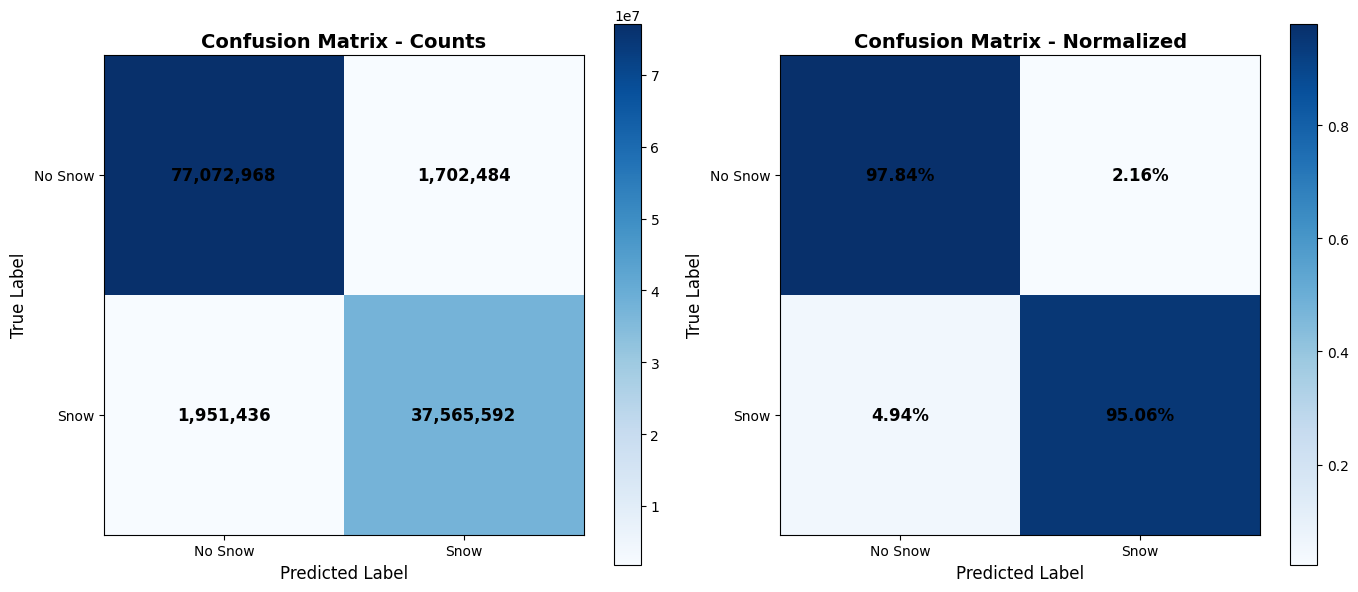


✓ Confusion matrix saved!

Pixel-level Classification:
  True Positives (TP):  37,565,592
  False Positives (FP): 1,702,484
  True Negatives (TN):  77,072,968
  False Negatives (FN): 1,951,436

  Accuracy: 96.91%
  Sensitivity (Recall): 95.06%
  Specificity: 97.84%


In [ ]:
print(f"\n{'='*80}")
print("CREATING CONFUSION MATRIX")
print(f"{'='*80}\n")

# Calculate confusion matrix metrics
tp_total = 0
fp_total = 0
tn_total = 0
fn_total = 0

model.eval()
with torch.no_grad():
    val_dataset_cm = (
        wds.WebDataset(wds_path)
        .decode("pil")
        .to_tuple("image.png", "mask.png")
        .map(lambda x: preprocess_sample({"image.png": x[0], "mask.png": x[1]}, val_transform))
    )

    for idx, (img, msk) in enumerate(tqdm(val_dataset_cm, total=CONFIG['val_size'], desc="Computing confusion matrix")):
        if idx >= CONFIG['val_size']:
            break

        img = img.unsqueeze(0).to(device)
        msk = msk.to(device)

        pred = model(img)
        pred_binary = (torch.sigmoid(pred.squeeze()) > 0.5).float()
        msk_binary = msk.squeeze()

        tp_total += ((pred_binary == 1) & (msk_binary == 1)).sum().item()
        fp_total += ((pred_binary == 1) & (msk_binary == 0)).sum().item()
        tn_total += ((pred_binary == 0) & (msk_binary == 0)).sum().item()
        fn_total += ((pred_binary == 0) & (msk_binary == 1)).sum().item()

# Create confusion matrix
cm = np.array([[tn_total, fp_total],
               [fn_total, tp_total]])

# Normalize
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Raw counts
im1 = ax1.imshow(cm, interpolation='nearest', cmap='Blues')
ax1.set_title('Confusion Matrix - Counts', fontsize=14, fontweight='bold')
ax1.set_ylabel('True Label', fontsize=12)
ax1.set_xlabel('Predicted Label', fontsize=12)
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['No Snow', 'Snow'])
ax1.set_yticklabels(['No Snow', 'Snow'])

for i in range(2):
    for j in range(2):
        ax1.text(j, i, f'{cm[i, j]:,}',
                ha="center", va="center", color="black", fontsize=12, fontweight='bold')

plt.colorbar(im1, ax=ax1)

# Normalized
im2 = ax2.imshow(cm_normalized, interpolation='nearest', cmap='Blues')
ax2.set_title('Confusion Matrix - Normalized', fontsize=14, fontweight='bold')
ax2.set_ylabel('True Label', fontsize=12)
ax2.set_xlabel('Predicted Label', fontsize=12)
ax2.set_xticks([0, 1])
ax2.set_yticks([0, 1])
ax2.set_xticklabels(['No Snow', 'Snow'])
ax2.set_yticklabels(['No Snow', 'Snow'])

for i in range(2):
    for j in range(2):
        ax2.text(j, i, f'{cm_normalized[i, j]:.2%}',
                ha="center", va="center", color="black", fontsize=12, fontweight='bold')

plt.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.savefig(os.path.join(results_path, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Confusion matrix saved!")
print(f"\nPixel-level Classification:")
print(f"  True Positives (TP):  {tp_total:,}")
print(f"  False Positives (FP): {fp_total:,}")
print(f"  True Negatives (TN):  {tn_total:,}")
print(f"  False Negatives (FN): {fn_total:,}")
print(f"\n  Accuracy: {((tp_total + tn_total) / (tp_total + fp_total + tn_total + fn_total)) * 100:.2f}%")
print(f"  Sensitivity (Recall): {(tp_total / (tp_total + fn_total)) * 100:.2f}%")
print(f"  Specificity: {(tn_total / (tn_total + fp_total)) * 100:.2f}%")
